# Isoprene Sensitivity Studies

---
Last modified: February 6th, 2025 (JY)

This notebook uses a modified version of vSmartMOM with functions specifically for isoprene to calculate radiances with different amounts of isoprene/water vapor/nitric acid/etc. This notebook is coded in Julia.

In [243]:
# Activate Julia packages
using Pkg;
Pkg.activate("../../"); # Activates the vSmartMOM.jl Project.toml file
Pkg.instantiate();

# Using local module, since the current version of vSmartMOM does not support isoprene (not a HITRAN line list species)
include("../../src/vSmartMOM.jl");
include("../helper_functions.jl");

# Other imports
using Revise, PlotlyBase, Plots, LinearAlgebra, NCDatasets, Format, LaTeXStrings, .vSmartMOM;
using FiniteDiff, DataFrames, CSV

default(fontfamily="Arial");

  Activating project at `~/Documents/Caltech/vSmartMOM.jl`
Precompiling project...
   4462.8 ms  ✓ PlotlyJS
   1617.5 ms  ✓ PlotlyJS → IJuliaExt
   8717.1 ms  ✓ PlotlyJS → CSVExt
   2087.3 ms  ✓ PlotlyJS → DataFramesExt
  4 dependencies successfully precompiled in 17 seconds. 395 already precompiled.


### We now need to specify parameters for the model.

I have downloaded 10 days (2019-07-01 to 2019-07-10) in the MERRA2 folder. You will need to manually download more days if you would like different conditions.

In [271]:
using NCDatasets
using Statistics

Na = 6.02214076e23
dryMass = 28.9647e-3 / Na      # kg molecule-1
wetMass = 18.01528e-3 / Na     # kg molecule-1
ratio = dryMass / wetMass

function read_atmos_profile(file::String, time_index::Integer; dimension = "1D", g₀=9.8196)
    ds = Dataset(file)

    # First, we have to take the spatial mean of these variables IF it is 3D
    if ( dimension == "3D" ) 
        T = dropdims(mean(ds["TABS"][:], dims=(1,2)), dims=(1,2))
        q = dropdims(mean(ds["QV"][:], dims=(1,2)), dims=(1,2))
        p_interface = ds["pi"][:]
        p_full = ds["p"][:]

    elseif ( dimension == "1D" ) 
        T = ds["TABS"][:, time_index] # In K
        q = ds["QV"][:, time_index] ./ 1000.   # In g/kg -> kg/kg
        p_full = ds["p"][:, time_index]

        # Reconstruct the pressure interfaces only with 1D data
        n = length(p_full)
        pi = zeros(Float64, n + 1)

        # Interior interfaces:
        # pi[k] lies halfway between p[k-1] and p[k]
        for k in 2:n
            pi[k] = (p_full[k-1] + p_full[k]) / 2
        end
        
        pi[1] = p_full[1] + (p_full[1] - p_full[2]) / 2             # Bottom interface
        pi[end] = p_full[end] + (p_full[end] - p_full[end-1]) / 2   # Top interface
    end

    close(ds)
    n_layers = length(p_full)
    
    dp = zeros(Float64, n_layers)

    for k in 1:n_layers
        if k == 1
            dp[k] = abs(p_full[2] - p_full[1])
        elseif k == n_layers
            dp[k] = abs(p_full[end] - p_full[end-1])
        else
            dp[k] = abs(p_full[k+1] - p_full[k-1]) / 2
        end
    end

    vmr_h2o = zeros(Float64, n_layers)
    vcd_dry = zeros(Float64, n_layers)
    vcd_h2o = zeros(Float64, n_layers)

    for k in 1:n_layers
        vmr_h2o[k] = q[k] * ratio 
        vmr_dry = 1.0 - vmr_h2o[k]

        # mean molecular mass of moist air
        M = vmr_dry * dryMass + vmr_h2o[k] * wetMass

        # molecules cm-2
        vcd_dry[k] = vmr_dry * dp[k] / (M * g₀ * 100^2)
        vcd_h2o[k] = vmr_h2o[k] * dp[k] / (M * g₀ * 100^2)
    end

    return (
        temperature = T,        # K
        specific_humidity = q,  # kg/kg
        pressure = p_full,      # Pa
        pressure_interfaces = pi,
        dp = dp,                # Pa
        vmr_h2o = vmr_h2o,      # mol/mol
        vcd_dry = vcd_dry,      # molecules/cm2
        vcd_h2o = vcd_h2o       # molecules/cm2
    )
end

read_atmos_profile (generic function with 2 methods)

In [273]:
filetype = "1D";
# filename = "Data/" * filetype * "/BORNEO_transport_loss_low_variability_higher_SM.nc";
filename = "Data/" * filetype * "/BORNEO_transport_loss_highest_variability_higher_SM.nc";
time_index = 488;
top_threshold = 150.0 # in hPa

ds = Dataset(filename)
profile = read_atmos_profile(filename, 1);
merra2_skin_temperature = ds["SST"][time_index];

pressures = vec(profile.pressure_interfaces);               # Already in mb (hPa)
pressures_midpoints = vec(profile.pressure);                     # Already in mb (hPa)
temperatures = vec(profile.temperature);                    # K
specific_humidity = vec(profile.specific_humidity);         # kg/kg;
h2o = vec(profile.vmr_h2o);

df = DataFrame(
    pressures_midpoints = profile.pressure,                   # Already in mb (hPa)
    temperatures        = vec(profile.temperature),               # K
    specific_humidity   = vec(profile.specific_humidity)        # Already in g/kg
)

pressures = df[!, "pressures_midpoints"][:]
mask = pressures .> top_threshold
df = df[mask, :]

mask_interfaces = vec(profile.pressure_interfaces) .> top_threshold

pressures = vec(profile.pressure_interfaces[mask_interfaces]);                     # Already in mb (hPa)
temperatures = vec(df.temperatures);                    # K
specific_humidity = vec(df.specific_humidity);         # kg/kg;

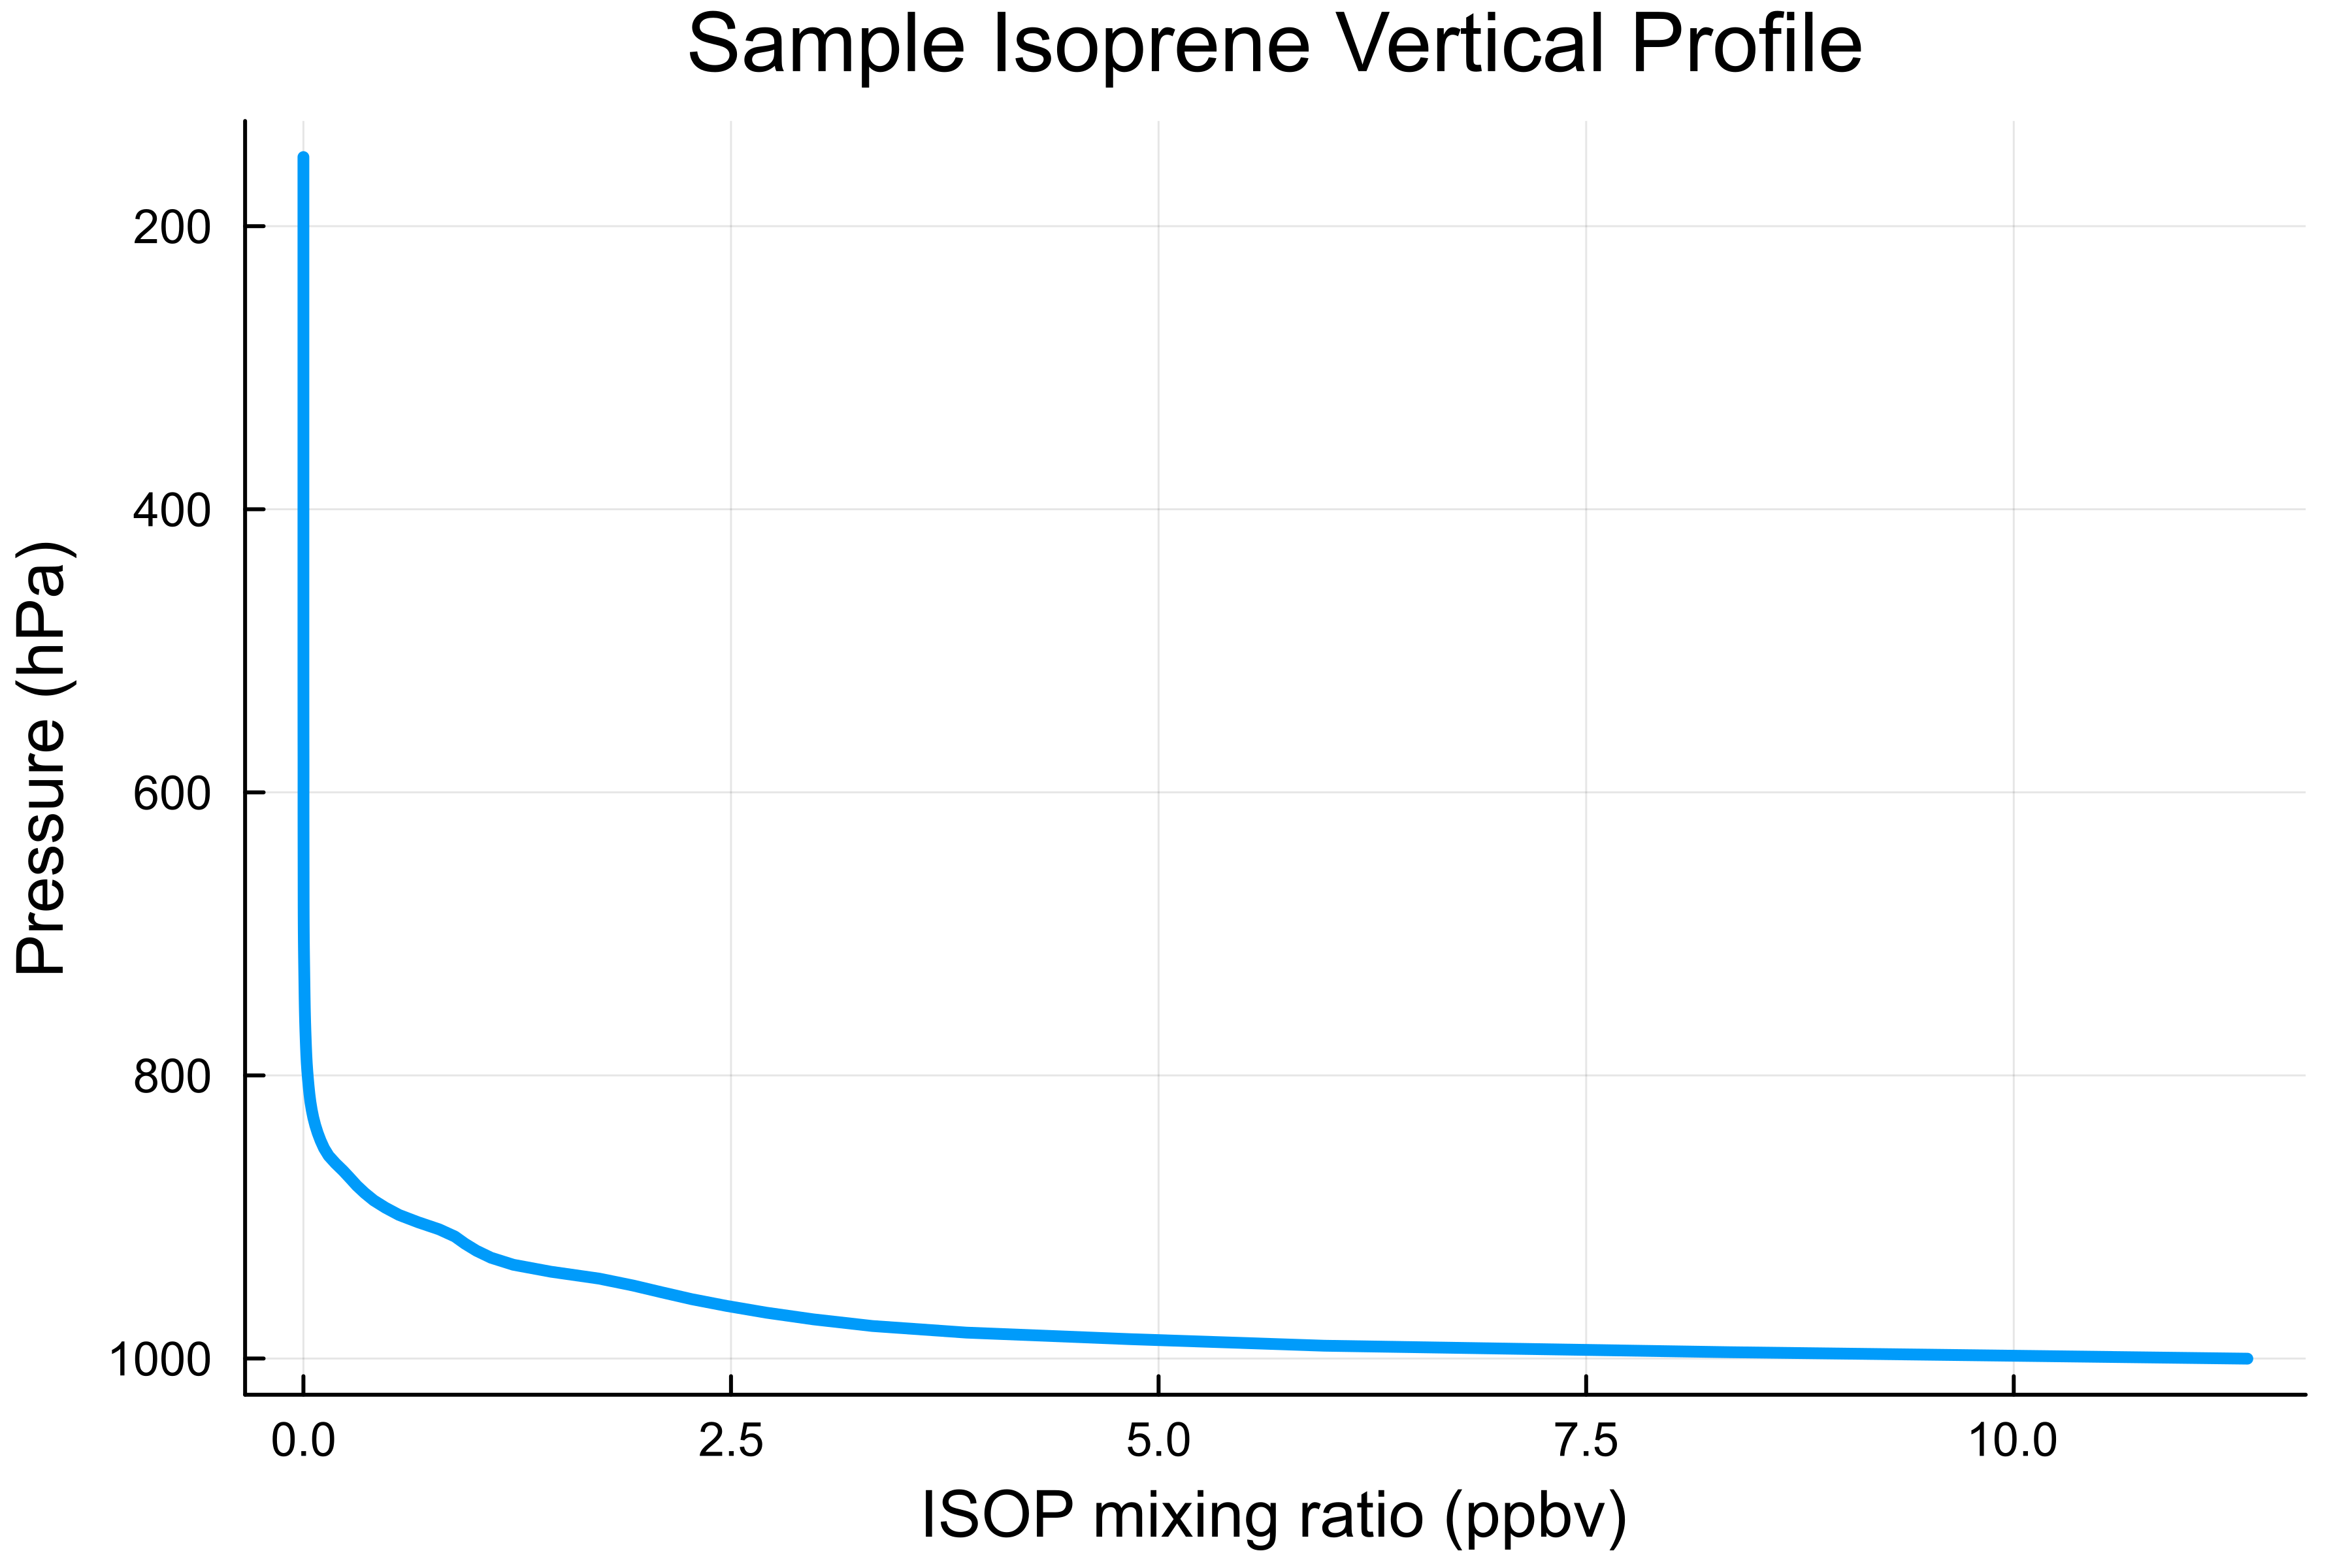

In [275]:
if (filetype == "1D")
    ISOP = ds["ISOP"][:, time_index]
else
    ISOP = dropdims(mean(ds["ISOP"][:], dims=(1,2)), dims=(1,2))
    ISOP = vec(ISOP)
end

df_masked_ISOP = ISOP[mask]

p = plot(df_masked_ISOP, df.pressures_midpoints, yflip = true, lw = 3, dpi = 600, label = "")

xlabel!("ISOP mixing ratio (ppbv)")
ylabel!("Pressure (hPa)")
title!("Sample Isoprene Vertical Profile")
# savefig(p, "Figures/isoprene_vertical_profile.png")

## Create instrument kernel!

In [278]:
import InstrumentOperator: FTSInstrument, create_instrument_kernel, FixedKernelInstrument, conv_spectra

ν_min = 890.
ν_max = 910.
Δν = 0.01
ν = ν_min:Δν:ν_max

x = -5:Δν:5
fov = 16.8 #mrads
mopd = 0.8 #cm
FTS = FTSInstrument(0.8, fov * 1e-3, 0.)
unapodized_fts = create_instrument_kernel(FTS, x, 900.0)

p = plot(x, unapodized_fts.parent,label="CrIS Unapodized FTS Lineshape",lw=2, dpi = 300, title = "CrIS Unapodized FTS Instrument Line Shape \n(FOV = 16.8 mrads, MOPD = 0.8 cm)")
ylabel!("Channel Response Function")
xlabel!("σ (cm^-1)")

margin = 0
sampling = 0.625
cris_instrument_kernel = FixedKernelInstrument(unapodized_fts, collect(ν_min+margin:sampling:ν_max-margin))

(Θ, β) = (0.12700800000000004, 0.0)


┌ Info: Center of OffsetArrays is 
└   minimum(abs.(grid_x)) = 0.0


FixedKernelInstrument{Float64}([-0.0001938027449118005, -0.00022515990131574464, -0.0002560745521885616, -0.0002864668905839412, -0.0003162580989748737, -0.0003453705508071965, -0.00037372800988458884, -0.00040125582708002165, -0.0004278811338732687, -0.00045353303222005073  …  -0.00011292824838757243, -9.056541516724512e-5, -7.058344327000462e-5, -5.30230478386403e-5, -3.791869420702852e-5, -2.529853680148194e-5, -1.5184374041206004e-5, -7.5916192866803565e-6, -2.5292878448332848e-6, -1.463672932855431e-18], [890.0, 890.625, 891.25, 891.875, 892.5, 893.125, 893.75, 894.375, 895.0, 895.625  …  904.375, 905.0, 905.625, 906.25, 906.875, 907.5, 908.125, 908.75, 909.375, 910.0])

# We can finally run the model!

In [281]:
pressures

184-element Vector{Float64}:
 1002.387939453125
  997.831787109375
  993.261962890625
  988.6621704101562
  984.0313720703125
  979.3713989257812
  974.684814453125
  969.97216796875
  965.232177734375
  960.4649658203125
  955.6697998046875
  950.8472290039062
  945.9989013671875
    ⋮
  176.88095092773438
  174.3052978515625
  171.7568359375
  169.23507690429688
  166.7398681640625
  164.2716827392578
  161.83035278320312
  159.41525268554688
  157.02615356445312
  154.6627960205078
  152.32501220703125
  150.0126495361328

In [283]:
parameters = vSmartMOM.CoreRT.parameters_from_yaml("yaml_files/no_absorption_890_910.yaml");

parameters.T = temperatures;
parameters.p = pressures;
parameters.q = specific_humidity;
parameters.surface_skin_temperature = merra2_skin_temperature;

model = vSmartMOM.CoreRT.model_from_parameters(parameters); # Create model from the YAML file
simulated_spectrum_control = vSmartMOM.CoreRT.rt_run(model); # Run the model
convolved_spectrum_control = conv_spectra(cris_instrument_kernel, ν, simulated_spectrum_control[1][1,1,:]);

(params.absorption_params.molecules[i_band])[molec_i] = "CO2"
Computing profile for CO2 with vmr [0.000395, 0.0003949462508218233, 0.00039489224461674454, 0.00039483787929295923, 0.0003947831595236838, 0.00039472811119134764, 0.000394672752629338, 0.0003946170795239168, 0.0003945610850449985, 0.00039450476559780114, 0.0003944481201038903, 0.00039439116150448054, 0.00039433388728322467, 0.00039427627263612786, 0.00039421832439327564, 0.00039416007346979194, 0.00039410151195715657, 0.00039404261505137495, 0.00039398339785053077, 0.0003939238819233151, 0.0003938640561259041, 0.00039380391111186523, 0.00039374345371128377, 0.00039368267637511793, 0.00039362157263276047, 0.00039356016045812047, 0.00039349845710615083, 0.0003934364629363298, 0.0003933741639290081, 0.0003933115464240148, 0.0003932486179703917, 0.0003931853997773518, 0.0003931218993939369, 0.00039305811106849593, 0.0003929940376768546, 0.0003929296907223147, 0.0003928650730807017, 0.0003928001732487137, 0.00039273498691261256,

[ Info: Warning, make sure that the VMR is interpolated correctly! Right now, it might be tricky


Progress: 100%|█████████████████████████████████████████| Time: 0:00:17


(params.absorption_params.molecules[i_band])[molec_i] = "O2"
Computing profile for O2 with vmr 0.21 for band #1
FT_dual = Float64
Finished initializing arrays
Fourier Moment: 0/2


┌ Info: Processing on: Main.vSmartMOM.Architectures.CPU()
│ With FT: Float64
│ Source Function Integration: true
└ Dimensions: (11, 11, 2001)
Looping over layers ... 100%|████████████████████████████| Time: 0:00:03


Fourier Moment: 1/2


Looping over layers ... 100%|████████████████████████████| Time: 0:00:04


Fourier Moment: 2/2


[ Info: Radiance Δ range in %: from 0.0 to 0.0 for m=1
Looping over layers ... 100%|████████████████████████████| Time: 0:00:03


───────────────────────────────────────────────────────────────────────────────────────
                                              Time                    Allocations      
                                     ───────────────────────   ────────────────────────
          Tot / % measured:                244s /  11.9%           53.6GiB /  97.9%    

Section                      ncalls     time    %tot     avg     alloc    %tot      avg
───────────────────────────────────────────────────────────────────────────────────────
Absorption Coeff                  2    17.1s   59.2%   8.56s   23.5GiB   44.8%  11.7GiB
RT Kernel                       549    11.4s   39.4%  20.8ms   24.8GiB   47.2%  46.2MiB
  interaction                   546    8.11s   28.1%  14.9ms   24.5GiB   46.7%  45.9MiB
    interaction inv1 bla        546    2.39s    8.3%  4.38ms   7.05GiB   13.4%  13.2MiB
    interaction inv2            546    1.89s    6.5%  3.45ms   7.05GiB   13.4%  13.2MiB
  elemental                    

[ Info: Radiance Δ range in %: from 0.0 to 0.0 for m=2


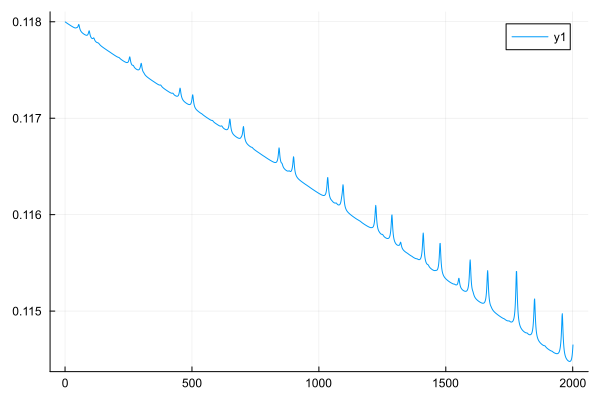

In [284]:
plot(simulated_spectrum_control[1][1,1,:])

In [285]:
parameters = vSmartMOM.CoreRT.parameters_from_yaml("yaml_files/CO2_O2_ISOP_H2O_absorption_890_910.yaml");

parameters.T = temperatures;
parameters.p = pressures;
parameters.q = specific_humidity;
parameters.surface_skin_temperature = merra2_skin_temperature;

parameters.absorption_params.vmr["ISOP"] = ds["ISOP"][:, time_index] * 1e-9;

model = vSmartMOM.CoreRT.model_from_parameters(parameters); # Create model from the YAML file
simulated_spectrum = vSmartMOM.CoreRT.rt_run(model); # Run the model
convolved_spectrum = conv_spectra(cris_instrument_kernel, ν, simulated_spectrum[1][1,1,:]);

[ Info: Warning, make sure that the VMR is interpolated correctly! Right now, it might be tricky
[ Info: Warning, make sure that the VMR is interpolated correctly! Right now, it might be tricky


(params.absorption_params.molecules[i_band])[molec_i] = "CO2"
Computing profile for CO2 with vmr [0.000395, 0.0003949462508218233, 0.00039489224461674454, 0.00039483787929295923, 0.0003947831595236838, 0.00039472811119134764, 0.000394672752629338, 0.0003946170795239168, 0.0003945610850449985, 0.00039450476559780114, 0.0003944481201038903, 0.00039439116150448054, 0.00039433388728322467, 0.00039427627263612786, 0.00039421832439327564, 0.00039416007346979194, 0.00039410151195715657, 0.00039404261505137495, 0.00039398339785053077, 0.0003939238819233151, 0.0003938640561259041, 0.00039380391111186523, 0.00039374345371128377, 0.00039368267637511793, 0.00039362157263276047, 0.00039356016045812047, 0.00039349845710615083, 0.0003934364629363298, 0.0003933741639290081, 0.0003933115464240148, 0.0003932486179703917, 0.0003931853997773518, 0.0003931218993939369, 0.00039305811106849593, 0.0003929940376768546, 0.0003929296907223147, 0.0003928650730807017, 0.0003928001732487137, 0.00039273498691261256,

Progress: 100%|█████████████████████████████████████████| Time: 0:00:16


(params.absorption_params.molecules[i_band])[molec_i] = "O2"
Computing profile for O2 with vmr 0.21 for band #1
(params.absorption_params.molecules[i_band])[molec_i] = "ISOP"
Computing profile for ISOP with vmr [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.2493493023902969e-54, 4.248393471688669e-53, 8.896418675082813e-52, 1.264842816267594e-50, 1.8329449600732218e-49, 2.1071278622904736e-48, 3.392836526478105e-47, 9.51236627457034e-46, 2.8073359538184277e-44, 1.2754415648943557e-42, 1.6748913075206827e-40, 2.577331218599365e-38, 2.56533723116012e-36, 1.581859671908615e-33, 9.578011873360744e-31, 1.25385503364192e-28, 3.766488103374895e-26, 7.647399229880037e-24, 7.227145693974152e-22, 2.6685205845073257e-20, 1.3865816483345203e-18, 2.2083299612408993e-17, 8.107818980355328e-17, 1.182177882707863e-16, 1.16985224840229e-16, 1.1355069413378015e-16, 1.1268183483064572e-16, 

Progress: 100%|█████████████████████████████████████████| Time: 0:01:54


FT_dual = Float64
Finished initializing arrays
Fourier Moment: 0/2


... (3 outputs left out)

Fourier Moment: 2/2


[ Info: Radiance Δ range in %: from 0.0 to 0.0 for m=1
Looping over layers ... 100%|████████████████████████████| Time: 0:00:03


───────────────────────────────────────────────────────────────────────────────────────
                                              Time                    Allocations      
                                     ───────────────────────   ────────────────────────
          Tot / % measured:                146s /  97.1%            156GiB /  98.8%    

Section                      ncalls     time    %tot     avg     alloc    %tot      avg
───────────────────────────────────────────────────────────────────────────────────────
Absorption Coeff                  3     132s   92.6%   43.9s    125GiB   81.1%  41.6GiB
RT Kernel                       549    10.2s    7.1%  18.5ms   24.8GiB   16.1%  46.2MiB
  interaction                   546    6.99s    4.9%  12.8ms   24.5GiB   15.9%  45.9MiB
    interaction inv1 bla        546    1.68s    1.2%  3.08ms   7.05GiB    4.6%  13.2MiB
    interaction inv2            546    1.67s    1.2%  3.07ms   7.05GiB    4.6%  13.2MiB
  elemental                    

[ Info: Radiance Δ range in %: from 0.0 to 0.0 for m=2


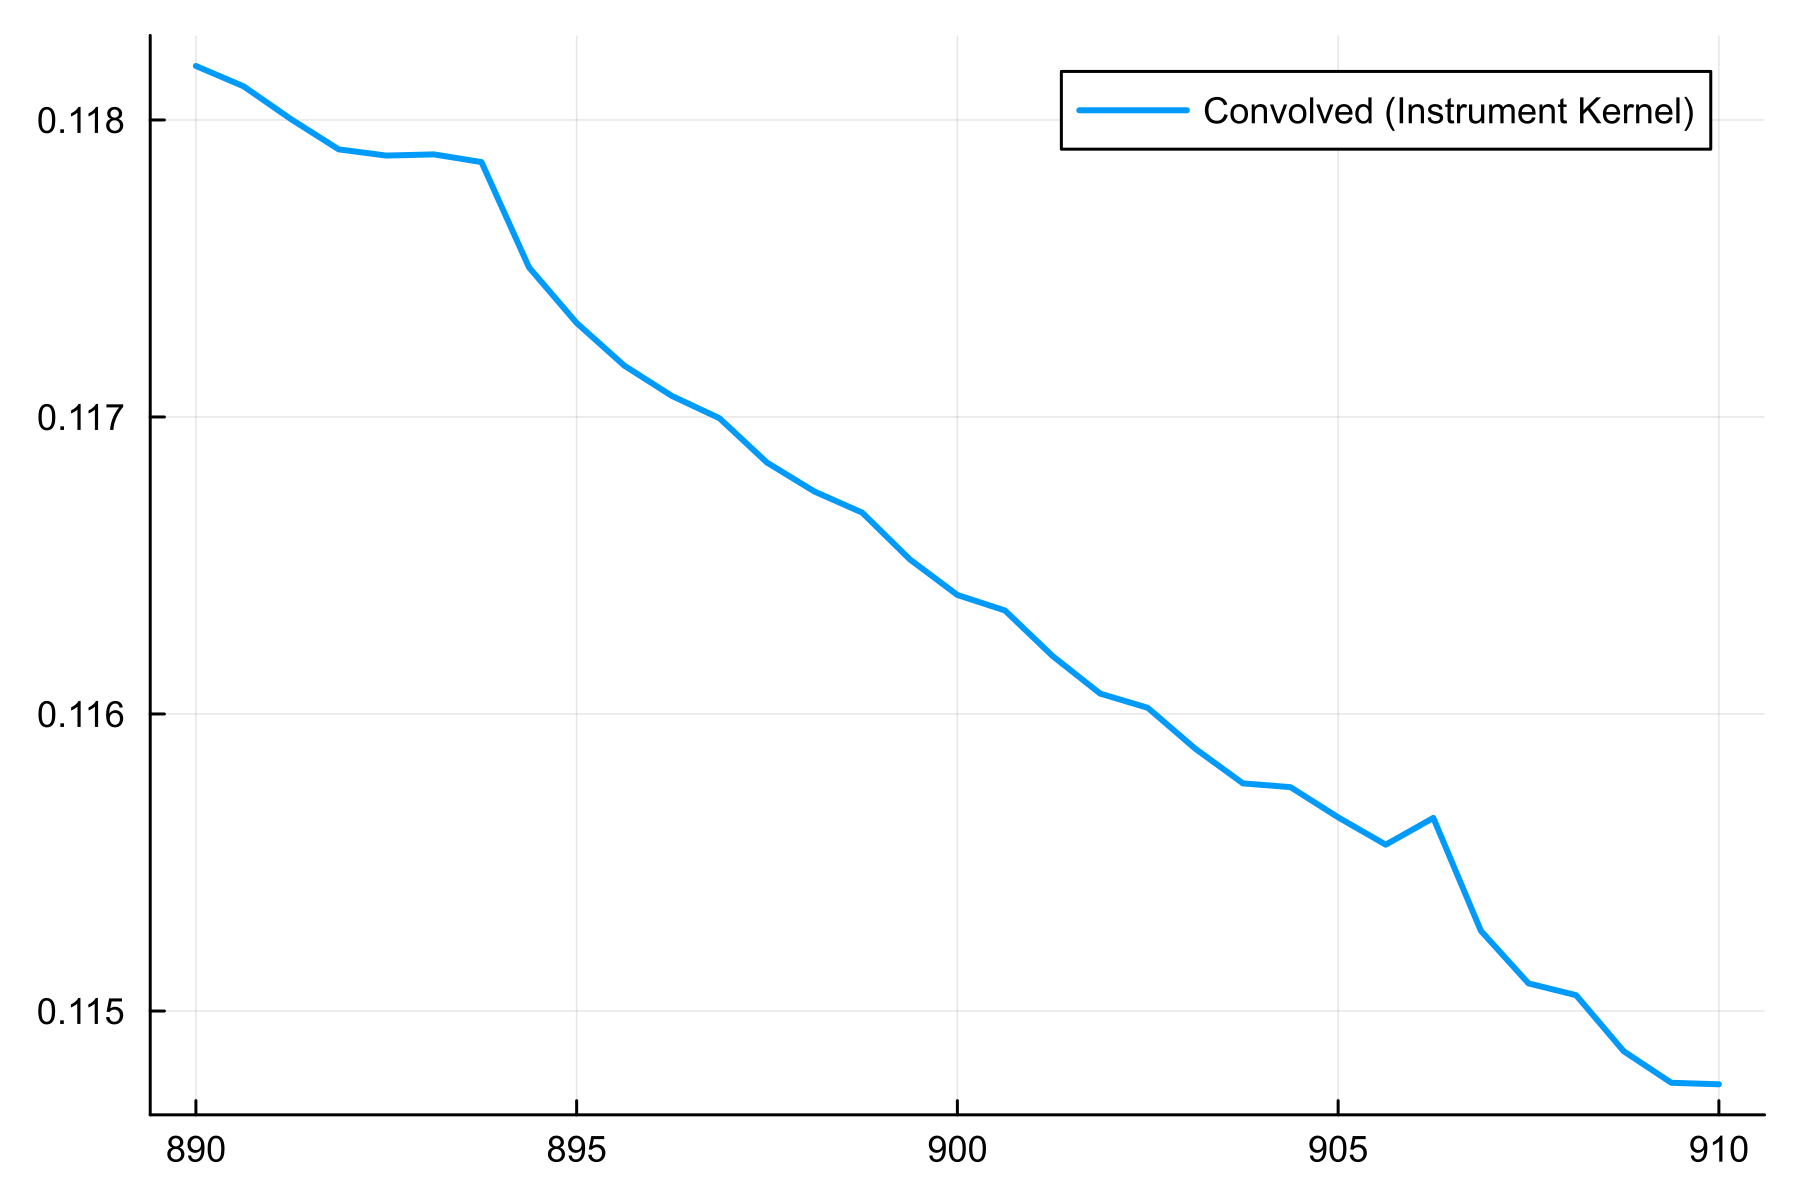

In [286]:
p = plot(cris_instrument_kernel.ν_out, convolved_spectrum, label="Convolved (Instrument Kernel)", lw = 2, dpi = 300)

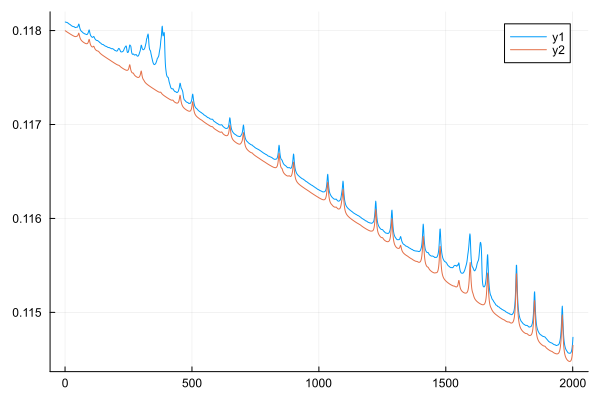

In [287]:
plot(simulated_spectrum[1][1,1,:])
plot!(simulated_spectrum_control[1][1,1,:])

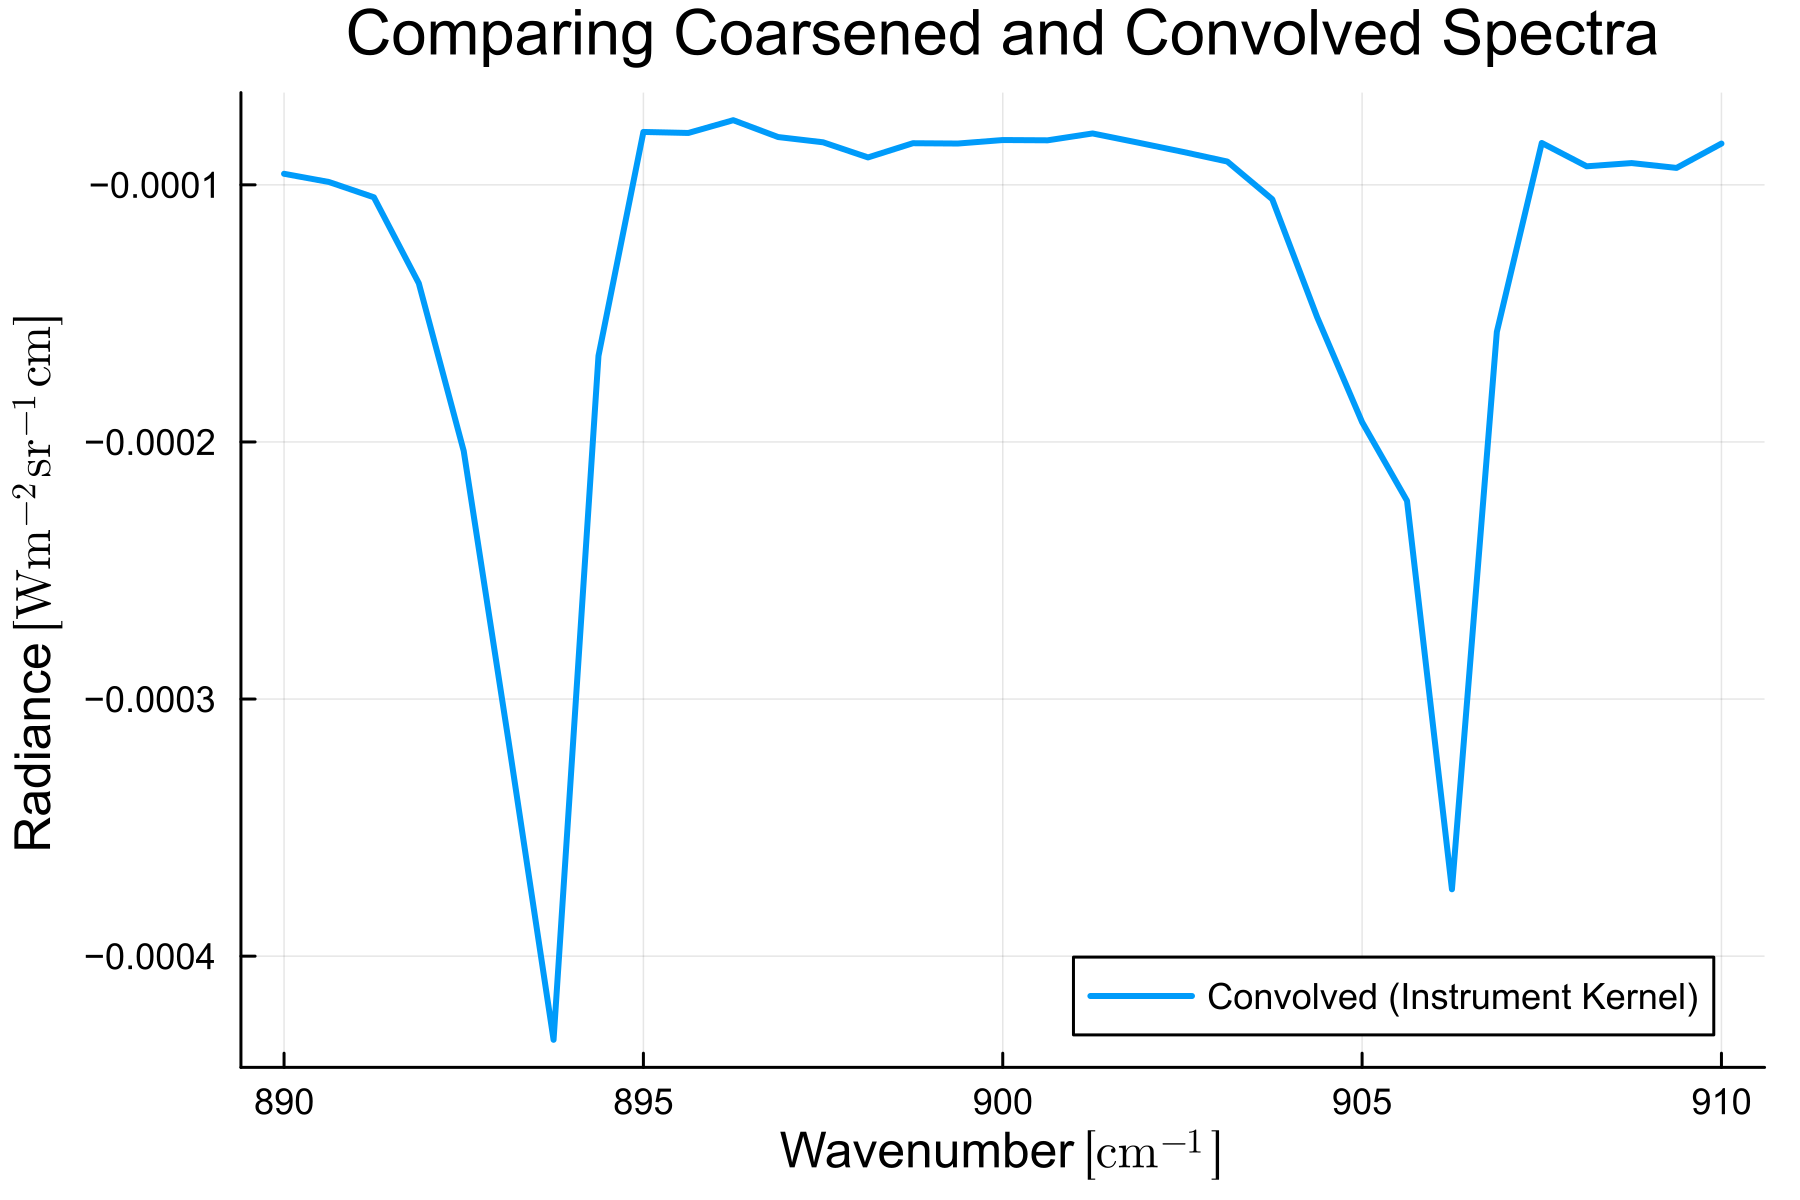

In [288]:
p = plot(cris_instrument_kernel.ν_out, convolved_spectrum_control - convolved_spectrum, label="Convolved (Instrument Kernel)", lw = 2, dpi = 300)

xlabel!(L"Wavenumber $\mathrm{[cm^{-1}]}$")
ylabel!(L"Radiance $\mathrm{[W m^{-2} sr^{-1} cm]}$")
title!("Comparing Coarsened and Convolved Spectra")

In [289]:
df = DataFrame(wavenumbers = cris_instrument_kernel.ν_out,
    experimental = convolved_spectrum,
    control = convolved_spectrum_control,
)
CSV.write("Data/high_soil_NOx_high_variability_488_spectra.csv", df)

"Data/high_soil_NOx_high_variability_488_spectra.csv"